# Torneo de modelos para predecir `SalePrice`

En este notebook se entrenan y comparan varios modelos de regresión para predecir el precio de venta de las viviendas. El objetivo es elegir el que mejor generaliza, es decir, el que se equivoca menos con viviendas que no vio durante el entrenamiento.

El flujo es el siguiente:

1. Se repite la misma división 80 % / 20 % del notebook de preprocesamiento.
2. Cada modelo se une con una copia sin ajustar del pipeline de preprocesamiento en un único `Pipeline`.
3. Los hiperparámetros de cada modelo se optimizan con **validación cruzada de 10 folds** (`GridSearchCV`), usando solo el 80 % de entrenamiento.
4. Cada modelo optimizado se evalúa en el **20 % de validación**, que no se usó en ningún paso anterior. Se reportan el RMSE en dólares reales y el RMSE normalizado al rango.
5. Se comparan los modelos con gráficas y se declara ganador al de menor RMSE real en validación.

## 1. Librerías

- **numpy**, **pandas** y **yaml**: manejo de datos y lectura de la configuración.
- **joblib**: carga del pipeline de preprocesamiento definido en el notebook anterior.
- **scikit-learn**:
  - `clone`: obtiene una copia sin ajustar del pipeline.
  - `KFold` y `GridSearchCV`: validación cruzada y búsqueda de hiperparámetros.
  - Los modelos del torneo.
  - La métrica de error.
- **matplotlib** y **seaborn**: gráficas de desempeño.

In [1]:
# Librerías
import os
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml
from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import ElasticNet, Lasso, Ridge
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

%matplotlib inline
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## 2. Carga de datos, configuración y pipeline de preprocesamiento

Se leen los **datos originales** (no los CSV procesados) y la lista de features de `pipeline_config.yaml`.

Los CSV de `data/processed/` se generaron con un pipeline ajustado sobre todo el 80 % de entrenamiento. Si se usaran en la validación cruzada, cada fold de validación ya habría influido en las medianas, los límites de outliers, el escalado, etc. Eso es una **fuga de datos**. Para evitarla, se carga el pipeline de preprocesamiento guardado y se obtiene una **copia sin ajustar** con `clone`, que conserva la misma configuración pero sin ningún valor aprendido. Esa copia se volverá a ajustar dentro de cada fold.

Nota: la lista de variables que transforma Yeo-Johnson (continuas con |sesgo| > 0.75) se decidió en el notebook anterior con el 80 % de entrenamiento. Es una decisión de diseño fija, al igual que la selección de features; lo que se re-aprende en cada fold son los parámetros de cada transformación.

In [2]:
# Carga de datos, features y copia sin ajustar del pipeline de preprocesamiento
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
DATA_DIR = Path(os.getenv("DATA_DIR", PROJECT_ROOT / "data" / "raw"))
CONFIG_FILE = PROJECT_ROOT / "pipeline_config.yaml"
PIPELINE_FILE = PROJECT_ROOT / "models" / "preprocessing_pipeline.joblib"
TRAIN_FILE = "train.csv"
TARGET = "SalePrice"

MODEL_FEATURES = yaml.safe_load(CONFIG_FILE.read_text(encoding="utf-8"))["MODEL_FEATURES"]
train = pd.read_csv(DATA_DIR / TRAIN_FILE)

preprocessing = clone(joblib.load(PIPELINE_FILE))

print(f"Train: {train.shape} | Features: {len(MODEL_FEATURES)}")
print(f"Pasos del preprocesamiento: {[name for name, _ in preprocessing.steps]}")

Train: (1460, 81) | Features: 30
Pasos del preprocesamiento: ['imputer_numericas', 'imputer_categoricas', 'encoder_ordinales', 'encoder_nominales', 'winsorizer', 'yeo_johnson', 'scaler']


## 3. División en entrenamiento y validación

Se repite **exactamente** la división del notebook de preprocesamiento: 20 % para validación y `random_state=42`. Así se garantiza que el conjunto de validación sea el mismo y que ninguna de sus viviendas se use para entrenar ni para elegir hiperparámetros.

El target se transforma con `log1p`, igual que antes. Los modelos aprenden a predecir el logaritmo del precio, y sus predicciones se regresan a dólares con `expm1` para calcular el error real.

In [3]:
# División 80/20 idéntica a la del notebook de preprocesamiento
TEST_SIZE = 0.2
RANDOM_STATE = 42

X_train, X_val, y_train, y_val = train_test_split(
    train[MODEL_FEATURES], train[TARGET], test_size=TEST_SIZE, random_state=RANDOM_STATE
)
y_train_log = np.log1p(y_train)
y_val_log = np.log1p(y_val)

print(f"Entrenamiento: {X_train.shape} | Validación: {X_val.shape}")

Entrenamiento: (1168, 30) | Validación: (292, 30)


## 4. Modelos del torneo y sus hiperparámetros

Se comparan seis modelos de tres familias distintas:

| Familia | Modelo | Idea |
|---|---|---|
| Regresión | **Ridge** | Regresión lineal que penaliza coeficientes grandes, lo que reduce el sobreajuste. |
| Regresión | **Lasso** | Regresión lineal que puede llevar a cero los coeficientes de variables poco útiles. |
| Regresión | **ElasticNet** | Combinación de Ridge y Lasso. |
| Ensamble | **Random Forest** | Promedio de muchos árboles de decisión entrenados con muestras distintas. |
| Ensamble | **Gradient Boosting** | Árboles que se entrenan en secuencia, cada uno corrigiendo los errores del anterior. |
| Red neuronal | **MLP** | Red neuronal artificial con capas ocultas. |

Para cada modelo se define una grilla de hiperparámetros, con al menos 3 configuraciones. Varias opciones de la grilla buscan controlar el **sobreajuste**:

- `alpha` en las regresiones y en la MLP: regularización.
- `max_depth` y `min_samples_leaf` en los árboles: limitan su complejidad. La grilla incluye valores restrictivos, como profundidad 8 u hojas de al menos 5 o 10 viviendas, porque una primera ejecución mostró que Random Forest y Gradient Boosting sobreajustaban con árboles sin restricciones.
- `subsample` en Gradient Boosting: cada árbol se entrena con una parte de los datos.
- `early_stopping` en la MLP: detiene el entrenamiento cuando deja de mejorar con datos internos de validación.

Las redes neuronales aprenden mal cuando el target está lejos de 0; el log del precio ronda 12. Por eso la MLP se envuelve en `TransformedTargetRegressor`, que estandariza el target antes de entrenar y revierte esa escala al predecir. El escalador del target también se ajusta dentro de cada fold, así que no introduce fuga de datos.

El prefijo `model__` indica que el parámetro pertenece al paso `model` del pipeline. En la MLP, `model__regressor__` apunta a la red que está dentro de `TransformedTargetRegressor`.

In [4]:
# Modelos y grillas de hiperparámetros
models = {
    "Ridge": (
        Ridge(),
        {"model__alpha": [0.1, 1, 10, 30, 100]},
    ),
    "Lasso": (
        Lasso(max_iter=50_000),
        {"model__alpha": [0.0001, 0.0005, 0.001, 0.005, 0.01]},
    ),
    "ElasticNet": (
        ElasticNet(max_iter=50_000),
        {"model__alpha": [0.0005, 0.001, 0.01], "model__l1_ratio": [0.2, 0.5, 0.8]},
    ),
    "RandomForest": (
        RandomForestRegressor(n_estimators=300, max_features=0.33, random_state=RANDOM_STATE, n_jobs=-1),
        {"model__max_depth": [8, 12, None], "model__min_samples_leaf": [1, 5, 10]},
    ),
    "GradientBoosting": (
        GradientBoostingRegressor(learning_rate=0.03, subsample=0.8, random_state=RANDOM_STATE),
        {"model__n_estimators": [300, 600], "model__max_depth": [2, 3], "model__min_samples_leaf": [1, 5, 10]},
    ),
    "MLP": (
        TransformedTargetRegressor(
            regressor=MLPRegressor(max_iter=2000, early_stopping=True, n_iter_no_change=20, random_state=RANDOM_STATE),
            transformer=StandardScaler(),
        ),
        {"model__regressor__hidden_layer_sizes": [(64,), (64, 32), (128, 64)], "model__regressor__alpha": [0.001, 0.01, 0.1]},
    ),
}

for name, (_, grid) in models.items():
    n_configs = int(np.prod([len(v) for v in grid.values()]))
    print(f"{name:<17} configuraciones: {n_configs}")

Ridge             configuraciones: 5
Lasso             configuraciones: 5
ElasticNet        configuraciones: 9
RandomForest      configuraciones: 9
GradientBoosting  configuraciones: 12
MLP               configuraciones: 9


## 5. Optimización de hiperparámetros con validación cruzada de 10 folds

Para cada modelo se arma un pipeline con dos pasos: **preprocesamiento → modelo**. Luego `GridSearchCV` prueba todas las configuraciones de su grilla de la siguiente manera:

1. El 80 % de entrenamiento se divide en **10 partes (folds)**.
2. Para cada configuración se entrena 10 veces: en cada vuelta se usan 9 folds para ajustar el preprocesamiento y el modelo, y el fold restante para medir el error.
3. Se promedia el error de las 10 vueltas y se elige la configuración con el menor error promedio.
4. El mejor pipeline se vuelve a ajustar con todo el 80 % de entrenamiento.

Como el preprocesamiento forma parte del pipeline, **se re-ajusta en cada fold** con los 9 folds de entrenamiento. Así, el fold de evaluación nunca influye en las transformaciones y no hay fuga de datos. El conjunto de validación no participa en este paso.

La métrica de la búsqueda es el **RMSE en escala logarítmica**, porque es la escala que aprende el modelo. También se registra el error en los folds de entrenamiento (`return_train_score=True`) para detectar sobreajuste.

In [5]:
# Búsqueda de hiperparámetros con CV de 10 folds para cada modelo
N_FOLDS = 10
cv = KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)

searches = {}
for name, (model, grid) in models.items():
    start = time.time()
    pipeline = Pipeline(steps=[("preprocessing", clone(preprocessing)), ("model", model)])
    search = GridSearchCV(
        pipeline,
        param_grid=grid,
        cv=cv,
        scoring="neg_root_mean_squared_error",
        return_train_score=True,
        n_jobs=-1,
    )
    search.fit(X_train, y_train_log)
    searches[name] = search
    print(f"{name:<17} RMSE CV (log): {-search.best_score_:.4f} | {time.time() - start:5.1f} s | {search.best_params_}")

Ridge             RMSE CV (log): 0.1263 |   9.9 s | {'model__alpha': 30}


Lasso             RMSE CV (log): 0.1261 |   4.9 s | {'model__alpha': 0.001}


ElasticNet        RMSE CV (log): 0.1261 |   6.4 s | {'model__alpha': 0.001, 'model__l1_ratio': 0.8}


RandomForest      RMSE CV (log): 0.1326 |  24.9 s | {'model__max_depth': None, 'model__min_samples_leaf': 1}


GradientBoosting  RMSE CV (log): 0.1221 |  37.0 s | {'model__max_depth': 3, 'model__min_samples_leaf': 5, 'model__n_estimators': 600}


MLP               RMSE CV (log): 0.1316 |  13.5 s | {'model__regressor__alpha': 0.1, 'model__regressor__hidden_layer_sizes': (128, 64)}


## 6. Evaluación en el conjunto de validación

Cada modelo optimizado predice el 20 % de validación, que no se usó en ninguna etapa anterior. Las predicciones están en escala logarítmica, así que se regresan a dólares con `expm1` antes de calcular las métricas del torneo:

- **RMSE real**: error típico de la predicción, en dólares. Es la raíz del promedio de los errores al cuadrado, por lo que penaliza más los errores grandes.
- **NRMSE**: RMSE real dividido entre el rango de precios del conjunto de entrenamiento (máximo − mínimo). Expresa el error como una proporción de ese rango, lo que facilita interpretarlo: 0.03 significa que el error típico es el 3 % del rango de precios.

Para analizar el sobreajuste se usa el RMSE en escala logarítmica en tres conjuntos, para que sean comparables entre sí:

- **Train**: promedio de los folds de entrenamiento en la CV.
- **CV**: promedio de los folds de evaluación.
- **Validación**: el 20 % reservado.

La columna `brecha_train_cv_%` indica cuánto peor es el error en CV que en entrenamiento. Una brecha grande significa que el modelo memoriza los datos de entrenamiento en lugar de generalizar.

In [6]:
# Métricas de cada modelo: RMSE real, NRMSE y RMSE log en train / CV / validación
price_range = y_train.max() - y_train.min()

rows, predictions = [], {}
for name, search in searches.items():
    best = search.best_index_
    pred_val = np.expm1(search.predict(X_val))
    predictions[name] = pred_val
    rmse_real = root_mean_squared_error(y_val, pred_val)
    rmse_train_log = -search.cv_results_["mean_train_score"][best]
    rmse_cv_log = -search.best_score_
    rows.append({
        "modelo": name,
        "rmse_real": rmse_real,
        "nrmse": rmse_real / price_range,
        "rmse_log_train": rmse_train_log,
        "rmse_log_cv": rmse_cv_log,
        "rmse_log_val": root_mean_squared_error(y_val_log, search.predict(X_val)),
        "brecha_train_cv_%": 100 * (rmse_cv_log - rmse_train_log) / rmse_train_log,
        "mejores_parametros": search.best_params_,
    })

results = pd.DataFrame(rows).sort_values("rmse_real").reset_index(drop=True)
print(f"Rango de precios en entrenamiento: {price_range:,.0f}")
results.style.format({
    "rmse_real": "{:,.0f}", "nrmse": "{:.4f}", "rmse_log_train": "{:.4f}",
    "rmse_log_cv": "{:.4f}", "rmse_log_val": "{:.4f}", "brecha_train_cv_%": "{:.1f}",
})

Rango de precios en entrenamiento: 710,100


,modelo,rmse_real,nrmse,rmse_log_train,rmse_log_cv,rmse_log_val,brecha_train_cv_%,mejores_parametros
0,GradientBoosting,"27,093",0.0382,0.0715,0.1221,0.1359,70.7,"{'model__max_depth': 3, 'model__min_samples_leaf': 5, 'model__n_estimators': 600}"
1,RandomForest,"28,753",0.0405,0.0504,0.1326,0.1448,162.8,"{'model__max_depth': None, 'model__min_samples_leaf': 1}"
2,Ridge,"29,854",0.0420,0.1244,0.1263,0.1346,1.6,{'model__alpha': 30}
3,MLP,"29,956",0.0422,0.1006,0.1316,0.1385,30.9,"{'model__regressor__alpha': 0.1, 'model__regressor__hidden_layer_sizes': (128, 64)}"
4,ElasticNet,"30,207",0.0425,0.1242,0.1261,0.1344,1.5,"{'model__alpha': 0.001, 'model__l1_ratio': 0.8}"
5,Lasso,"30,237",0.0426,0.1243,0.1261,0.1344,1.5,{'model__alpha': 0.001}


## 7. Gráfica: precio real vs. precio predicho

Para cada modelo se compara el precio real de cada vivienda de validación (eje X) con el que predijo el modelo (eje Y), ambos en dólares. La línea roja punteada es la predicción perfecta (y = x).

- Cuanto más cerca de la línea estén los puntos, mejor es el modelo.
- Si los puntos se alejan de la línea en los precios altos, el modelo tiene dificultades con las viviendas caras.
- Un patrón sistemático por encima o por debajo de la línea indica que el modelo sobrestima o subestima los precios.

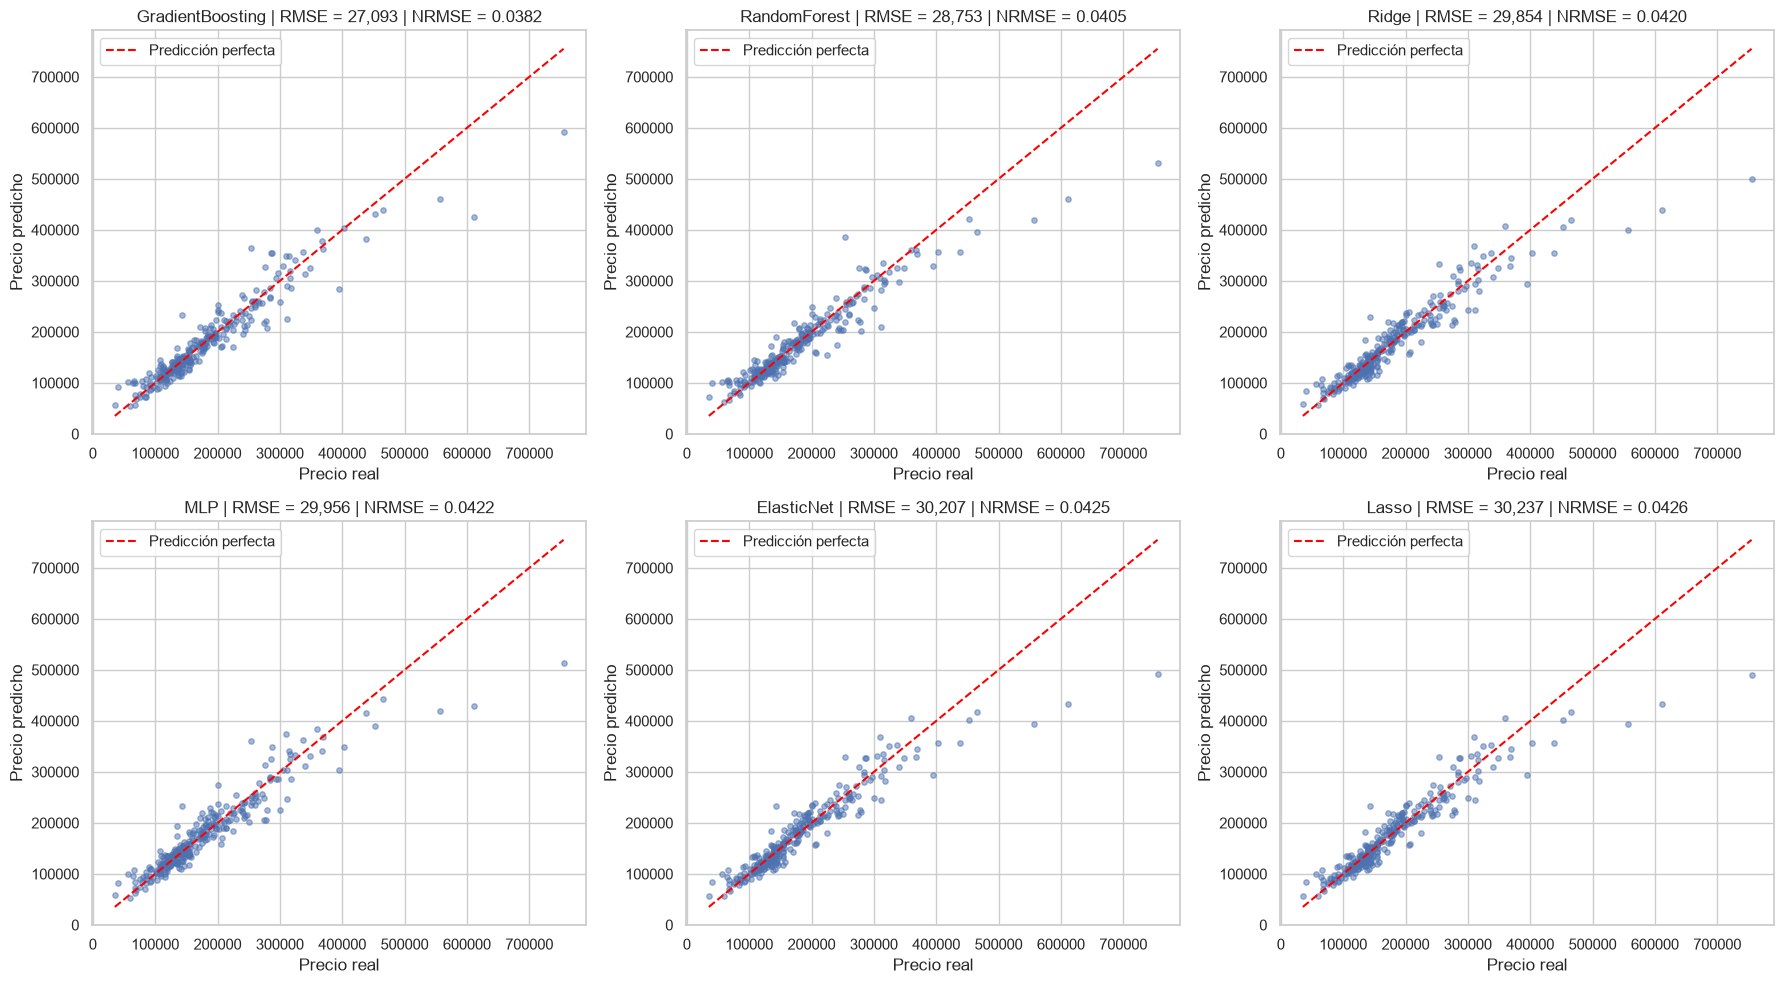

In [7]:
# Real vs. predicho en validación para cada modelo
n_cols = 3
n_rows = int(np.ceil(len(predictions) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 5 * n_rows))
axes = axes.flatten()
limits = [min(y_val.min(), min(p.min() for p in predictions.values())),
          max(y_val.max(), max(p.max() for p in predictions.values()))]

for ax, (_, row) in zip(axes, results.iterrows()):
    ax.scatter(y_val, predictions[row["modelo"]], alpha=0.5, s=15)
    ax.plot(limits, limits, color="red", linestyle="--", label="Predicción perfecta")
    ax.set_title(f"{row['modelo']} | RMSE = {row['rmse_real']:,.0f} | NRMSE = {row['nrmse']:.4f}")
    ax.set_xlabel("Precio real")
    ax.set_ylabel("Precio predicho")
    ax.legend()

for ax in axes[len(predictions):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

## 8. Gráfica: comparación de RMSE real y NRMSE

Se muestran lado a lado el RMSE real (en dólares) y el NRMSE de cada modelo sobre el conjunto de validación, ordenados de mejor a peor. La barra más corta corresponde al modelo con menor error.

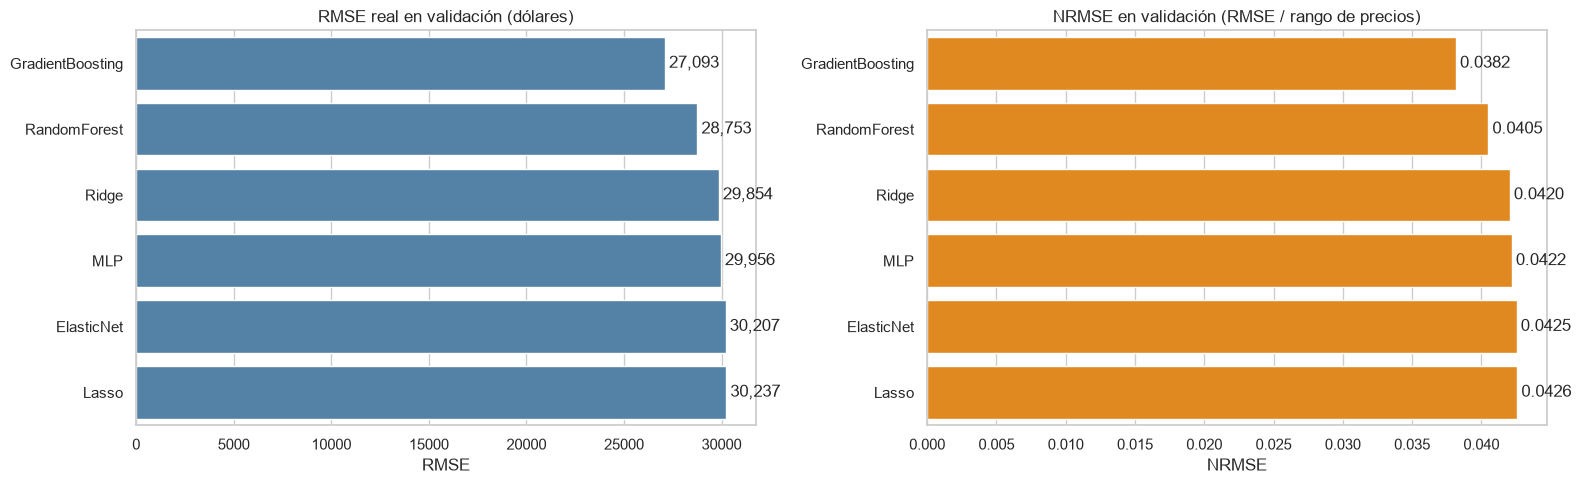

In [8]:
# Comparación de RMSE real y NRMSE en validación
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.barplot(data=results, x="rmse_real", y="modelo", ax=axes[0], color="steelblue")
axes[0].set_title("RMSE real en validación (dólares)")
axes[0].set_xlabel("RMSE")
axes[0].set_ylabel("")
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="{:,.0f}", padding=3)

sns.barplot(data=results, x="nrmse", y="modelo", ax=axes[1], color="darkorange")
axes[1].set_title("NRMSE en validación (RMSE / rango de precios)")
axes[1].set_xlabel("NRMSE")
axes[1].set_ylabel("")
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="{:.4f}", padding=3)

plt.tight_layout()
plt.show()

## 9. Gráfica: sobreajuste (train vs. CV vs. validación)

Para cada modelo se comparan tres errores (RMSE en escala logarítmica):

- **Train**: error en los datos con los que se entrenó, promediado en la CV.
- **CV**: error en los folds de evaluación de la CV.
- **Validación**: error en el 20 % reservado.

Un modelo que generaliza bien tiene las tres barras de altura parecida. Si la barra de **train** es mucho más baja que las otras dos, el modelo está **sobreajustado**: aprende muy bien los datos de entrenamiento, pero no se desempeña igual con datos nuevos. Que CV y validación sean parecidos confirma que la estimación de la validación cruzada es confiable.

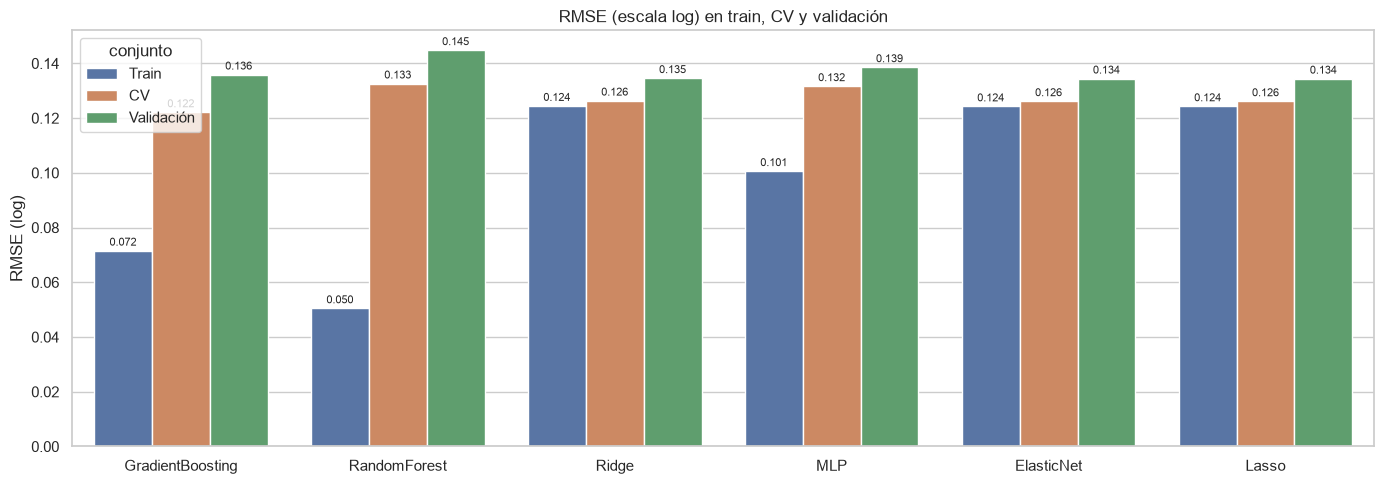

In [9]:
# Comparación de RMSE log en train, CV y validación por modelo
overfit = results.melt(
    id_vars="modelo",
    value_vars=["rmse_log_train", "rmse_log_cv", "rmse_log_val"],
    var_name="conjunto",
    value_name="rmse_log",
).replace({"conjunto": {"rmse_log_train": "Train", "rmse_log_cv": "CV", "rmse_log_val": "Validación"}})

fig, ax = plt.subplots(figsize=(14, 5))
sns.barplot(data=overfit, x="modelo", y="rmse_log", hue="conjunto", ax=ax)
ax.set_title("RMSE (escala log) en train, CV y validación")
ax.set_xlabel("")
ax.set_ylabel("RMSE (log)")
for container in ax.containers:
    ax.bar_label(container, fmt="{:.3f}", padding=2, fontsize=8)
plt.tight_layout()
plt.show()

## 10. Ganador del torneo

Gana el modelo con el **menor RMSE real en el conjunto de validación**. También se muestra su brecha entre train y CV, como alerta: si es grande, conviene revisar la gráfica de sobreajuste antes de dar el resultado por bueno.

In [10]:
# Ganador: menor RMSE real en validación
winner = results.iloc[0]
print(f"Ganador: {winner['modelo']}")
print(f"  RMSE real en validación: {winner['rmse_real']:,.0f}")
print(f"  NRMSE en validación:     {winner['nrmse']:.4f}")
print(f"  Brecha train vs. CV:     {winner['brecha_train_cv_%']:.1f} %")
print(f"  Mejores parámetros:      {winner['mejores_parametros']}")

Ganador: GradientBoosting
  RMSE real en validación: 27,093
  NRMSE en validación:     0.0382
  Brecha train vs. CV:     70.7 %
  Mejores parámetros:      {'model__max_depth': 3, 'model__min_samples_leaf': 5, 'model__n_estimators': 600}


## 11. Guardado del modelo ganador

El modelo ganador se guarda en `models/best_model.joblib` para usarlo en el notebook de inferencia. Antes de guardarlo se prepara así:

1. **Misma configuración**: se toma una copia sin ajustar del pipeline ganador, que incluye el preprocesamiento completo y el modelo con sus mejores hiperparámetros.
2. **Predicción en dólares**: se envuelve en `TransformedTargetRegressor`. Aplica `log1p` al precio al entrenar y `expm1` a las predicciones, de modo que el modelo recibe y devuelve precios en dólares sin pasos manuales.
3. **Re-entrenamiento con el 100 % de `train.csv`** (entrenamiento + validación). Los hiperparámetros ya se eligieron sin ver el conjunto de validación, así que usar todos los datos en este paso no introduce fuga. Solo le da al modelo más ejemplos para aprender. Las métricas del torneo siguen siendo la estimación de su desempeño.

In [11]:
# Re-entrenamiento del ganador con todo train.csv y guardado
MODELS_DIR = PROJECT_ROOT / "models"
BEST_MODEL_FILE = MODELS_DIR / "best_model.joblib"

winner_name = winner["modelo"]
best_model = TransformedTargetRegressor(
    regressor=clone(searches[winner_name].best_estimator_),
    func=np.log1p,
    inverse_func=np.expm1,
)
best_model.fit(train[MODEL_FEATURES], train[TARGET])

joblib.dump(best_model, BEST_MODEL_FILE)
print(f"Modelo ganador ({winner_name}) guardado en: {BEST_MODEL_FILE.relative_to(PROJECT_ROOT)}")
print(f"Entrenado con {len(train)} viviendas | Pasos: {[name for name, _ in best_model.regressor_.steps]}")

Modelo ganador (GradientBoosting) guardado en: models\best_model.joblib
Entrenado con 1460 viviendas | Pasos: ['preprocessing', 'model']
